In [1]:
from mira.openai_utility import OpenAIClient
from mira.sources.sympy_ode.paper_extraction import get_template_model_from_pmid
from mira.modeling import Model
from mira.modeling.ode import OdeModel
from IPython.display import Image
import logging

logging.getLogger().setLevel(logging.WARNING)

client = OpenAIClient(max_completion_tokens=32768)

## We first run ODE extraction using markdown text extracted from the documents

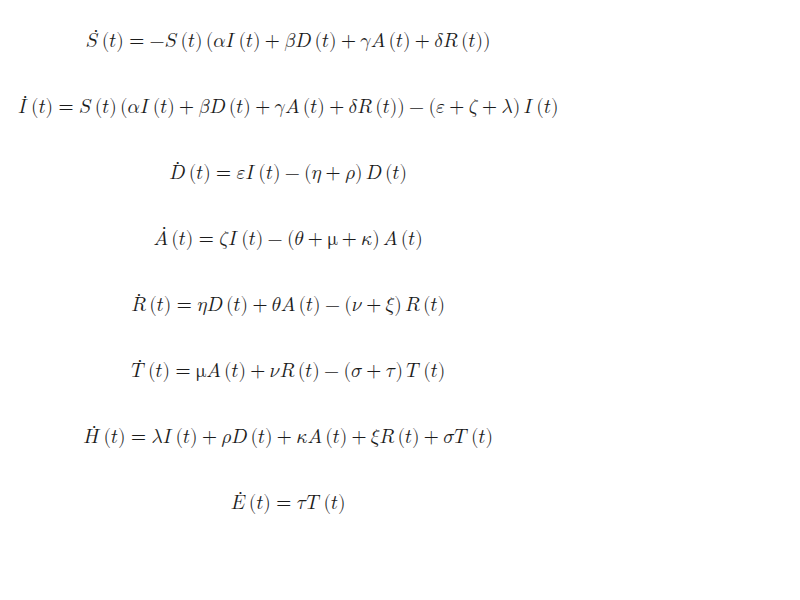

In [2]:
biomodel_name = "BIOMD0000000955"

image_path = f"images/{biomodel_name}.png"
Image(image_path)

In [3]:
tm, ode, scenarios = get_template_model_from_pmid(
    "41413153", extractor="xml", client=client)
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

Matrix([
[Derivative(If, t), =, -If*(gamma1 + mu0) + 2*Sf*a*betamf*cmf*(Cm*epsilon + Im)/(Cf + Cm + If + Im + R + Sf + Sm) + 2*Sf*betaff*cff*(1 - a)*(Cf*epsilon + If)/(Cf + Cm + If + Im + R + Sf + Sm) + Sf*(beta*epsilon*(Cf + Cm) + beta*(If + Im))],
[Derivative(Cf, t), =,                                                                                                                                                                  -Cf*(delta*thetaf + gamma2 + mu0 + mu1) + If*gamma1*qf],
[Derivative(Cm, t), =,                                                                                                                                                                  -Cm*(delta*thetam + gamma2 + mu0 + mu1) + Im*gamma1*qm],
[Derivative(Sm, t), =,  Am - 2*Sm*b*betafm*cfm*(Cf*epsilon + If)/(Cf + Cm + If + Im + R + Sf + Sm) - 2*Sm*betamm*cmm*(1 - b)*(Cm*epsilon + Im)/(Cf + Cm + If + Im + R + Sf + Sm) - Sm*(beta*epsilon*(Cf + Cm) + beta*(If + Im) + gamma3 + mu0)],
[Derivative(Im, t), =, -Im*

In [4]:
scenarios

[Scenario('default', parameters=[Parameter('a', value=0.75, units=Unit(1)), Parameter('b', value=0.75, units=Unit(1)), Parameter('Af', value=8304000.0, units=Unit(1/year)), Parameter('Am', value=8304000.0, units=Unit(1/year)), Parameter('mu0', value=0.0069, units=Unit(1/year)), Parameter('mu1', value=0.002, units=Unit(1/year)), Parameter('epsilon', value=0.16, units=Unit(1)), Parameter('gamma1', value=0.26, units=Unit(1/year)), Parameter('gamma2', value=0.025, units=Unit(1/year)), Parameter('gamma3', value=0.05, units=Unit(1/year)), Parameter('qf', value=0.05, units=Unit(1)), Parameter('qm', value=0.07, units=Unit(1)), Parameter('beta', value=3.5e-11, units=Unit(1/year)), Parameter('betamf', value=2.26e-07, units=Unit(1)), Parameter('betafm', value=0.00306, units=Unit(1)), Parameter('betaff', value=0.0142, units=Unit(1)), Parameter('betamm', value=0.00973, units=Unit(1)), Parameter('cmf', value=21.8, units=Unit(1/year)), Parameter('cfm', value=21.8, units=Unit(1/year)), Parameter('cff'

In [5]:
scenarios[0]

Scenario('default', parameters=[Parameter('a', value=0.75, units=Unit(1)), Parameter('b', value=0.75, units=Unit(1)), Parameter('Af', value=8304000.0, units=Unit(1/year)), Parameter('Am', value=8304000.0, units=Unit(1/year)), Parameter('mu0', value=0.0069, units=Unit(1/year)), Parameter('mu1', value=0.002, units=Unit(1/year)), Parameter('epsilon', value=0.16, units=Unit(1)), Parameter('gamma1', value=0.26, units=Unit(1/year)), Parameter('gamma2', value=0.025, units=Unit(1/year)), Parameter('gamma3', value=0.05, units=Unit(1/year)), Parameter('qf', value=0.05, units=Unit(1)), Parameter('qm', value=0.07, units=Unit(1)), Parameter('beta', value=3.5e-11, units=Unit(1/year)), Parameter('betamf', value=2.26e-07, units=Unit(1)), Parameter('betafm', value=0.00306, units=Unit(1)), Parameter('betaff', value=0.0142, units=Unit(1)), Parameter('betamm', value=0.00973, units=Unit(1)), Parameter('cmf', value=21.8, units=Unit(1/year)), Parameter('cfm', value=21.8, units=Unit(1/year)), Parameter('cff',

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "42733584", extractor="mineru", client=client)
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

In [6]:
tm, ode, scenarios = get_template_model_from_pmid(
    "26197242", extractor="xml", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

concept name	identifiers	context
I	{'ido': '0000511'}	{}
D	{'ncit': 'C28554'}	{}
R	{'ido': '0000592'}	{}
H	{'ido': '0000511'}	{'hospitalization': 'ncit:C25179'}
S	{'ido': '0000514'}	{}
E	{'apollosv': '00000154'}	{}


Matrix([
[Derivative(I, t), =,                        E*alpha + H*kappa - I*eta - I*gamma],
[Derivative(D, t), =,                     -D*b + H*deltaH*gammaH + I*delta*gamma],
[Derivative(R, t), =,                H*gammaH*(1 - deltaH) + I*gamma*(1 - delta)],
[Derivative(S, t), =,                     -S*(D*phi1/N + H*theta1/N + I*beta1/N)],
[Derivative(H, t), =, -H*deltaH*gammaH - H*gammaH*(1 - deltaH) - H*kappa + I*eta],
[Derivative(E, t), =,           -E*alpha + S*(D*phi1/N + H*theta1/N + I*beta1/N)]])

In [7]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32322102", extractor="xml", client=client)
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

Matrix([
[Derivative(I, t), =, -I*(epsilon + lambda + zeta) + S*(A*gamma + D*beta + I*alpha + R*delta)],
[Derivative(A, t), =,                                        -A*(kappa + mu + theta) + I*zeta],
[Derivative(D, t), =,                                              -D*(eta + rho) + I*epsilon],
[Derivative(H, t), =,                             A*kappa + D*rho + I*lambda + R*xi + T*sigma],
[Derivative(R, t), =,                                           A*theta + D*eta - R*(nu + xi)],
[Derivative(T, t), =,                                           A*mu + R*nu - T*sigma - T*tau],
[Derivative(S, t), =,                               -S*(A*gamma + D*beta + I*alpha + R*delta)],
[Derivative(E, t), =,                                                                   T*tau]])

In [ ]:
biomodel_name = "BIOMD0000000962"

image_path = f"images/{biomodel_name}.png"
Image(image_path)

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32219006", ode_extraction_method="text", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

In [ ]:
biomodel_name = "BIOMD0000000972"

image_path = f'images/{biomodel_name}.png'
Image(image_path)

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32099934", ode_extraction_method="text", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

In [ ]:
biomodel_name = "BIOMD0000000991"
image_path = f'images/{biomodel_name}.png'
Image(image_path)

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32834593", ode_extraction_method="text", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

## We now run image based ODE extraction

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32322102", ode_extraction_method="image", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32219006", ode_extraction_method="image", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32099934", ode_extraction_method="image", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()

In [ ]:
tm, ode, scenarios = get_template_model_from_pmid(
    "32834593", ode_extraction_method="image", client=client)
print("concept name\tidentifiers\tcontext")
for concept in tm.get_concepts_map().values():
    print(f"{concept.name}\t{concept.identifiers}\t{concept.context}")
om = OdeModel(Model(tm), initialized=True)
om.get_interpretable_kinetics()